<h2>Birch</h2>
We decided to use birch because it's fast.

Rereading the file:

In [12]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score, adjusted_rand_score, rand_score
from sklearn.feature_extraction import text
from sklearn.decomposition import PCA
import nltk
nltk.download('wordnet')
nltk.download('punkt_tab')
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.cluster import Birch
from collections import Counter
from wordcloud import WordCloud


[nltk_data] Downloading package wordnet to /home/jack/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to /home/jack/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


<h2>File reading</h2>

In [5]:
data = pd.read_csv("data_unsupervised.csv", encoding="utf8")[1000:2000] #load data

#remove every character that is not a letter or a number
data['body'] = data['body'].str.replace(r'[^a-zA-Z0-9\s]', '', regex=True)
data['body'] = data['body'].str.lower() #convert to lowercase

data = data.drop_duplicates()#drop duplicates
data = data.dropna() #drop empty rows

#lemmatize data
lemmatizer = WordNetLemmatizer()
data['body'] = data['body'].apply(lambda x: ' '.join([lemmatizer.lemmatize(word) for word in word_tokenize(x)]))

In [6]:
# Count word frequencies in the 'body' column
word_counts = data['body'].str.split().explode().value_counts()

# Get words that appear only once
words_once = set(word_counts[word_counts == 1].index)

# Get most frequent words (e.g., top 20)
most_freq_words = set(word_counts.nlargest(20).index)

# Combine with wordsToRemove
remove_words = words_once | most_freq_words

def remove_selected_words(text):
    return ' '.join([word for word in text.split() if word not in remove_words])

data['body'] = data['body'].apply(remove_selected_words)

data['body'] = data['body'].str.strip() #remove leading and trailing whitespace
data = data[~(data['body'] == '')] #drop empty comments

In [7]:
vectorizer = TfidfVectorizer()
vectorizedData = vectorizer.fit_transform(data['body'])

<h2>Clustering</h2>

In [ ]:
# Parameter grids
thresholds = [0.001, 0.05, 0.3, 0.5, 0.7]
branching_factors = [25, 50, 75]
n_clusters_options = [3,5,7]  #n_clusters_options = None means no final clustering step

best_score = -1
best_params = None

for t in thresholds:
    for bf in branching_factors:
        for nc in n_clusters_options:
            #print("Testing parameters: threshold={}, branching_factor={}, n_clusters={}".format(t, bf, nc))
            birch = Birch(threshold=t, branching_factor=bf, n_clusters=nc)
            labels = birch.fit_predict(vectorizedData)

            try:
                score = silhouette_score(
                    vectorizedData,
                    labels,
                    n_samples=100000
                )
                if score > best_score:
                    best_score = score
                    best_params = {
                        'threshold': t,
                        'branching_factor': bf,
                        'n_clusters': nc
                    }
            except ValueError:
                # If silhouette_score raises ValueError, it means there's only one cluster in the sample choosen
                continue

print("Best score:", best_score)
print("Best parameters:", best_params)

#train the model with the best params
best_birch = Birch(**best_params)
best_birch.fit(vectorizedData)

Best score: -3.1760204731846745e-05
Best parameters: {'threshold': 0.7, 'branching_factor': 25, 'n_clusters': 3}


,threshold,0.7
,branching_factor,25
,n_clusters,3
,compute_labels,True
,copy,'deprecated'


<h2>User Distribution Analysis</h2>

Number of clusters found: 3


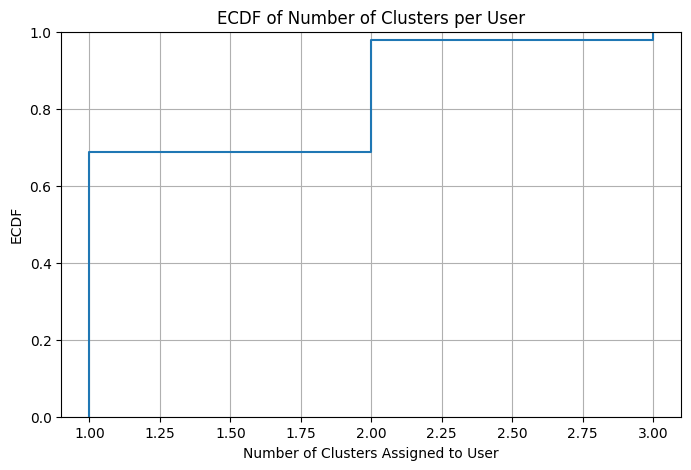

In [11]:
number_of_clusters = len(set(best_birch.labels_))
print("Number of clusters found:", number_of_clusters)

data["cluster"]= best_birch.labels_
user_clusters = data.groupby('author')['cluster'].nunique().reset_index()#grouping by author
#user clusters is now a series with author and number of clusters
user_clusters.columns = ['author', 'num_clusters']#turn it into a DF

# Filter user_clusters to only those authors who have multiple comments
authors_with_multiple_comments = data.groupby('author')['body'].nunique()
authors_with_multiple_comments = authors_with_multiple_comments[authors_with_multiple_comments > 1].index
user_clusters = user_clusters[user_clusters['author'].isin(authors_with_multiple_comments)]

plt.figure(figsize=(8, 5))
sns.ecdfplot(data=user_clusters, x='num_clusters')
plt.xlabel('Number of Clusters Assigned to User')
plt.ylabel('ECDF')
plt.title('ECDF of Number of Clusters per User')
plt.grid(True)
plt.show()

In [ ]:
#TODO
#Use the first two components of the PCA (found in Section 1.4). Then visualize on these two dimensions to gain insights into their distribution and separability.

<h3>Cluster analysis</h3>

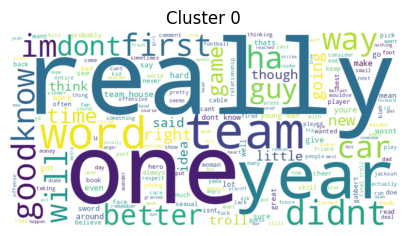

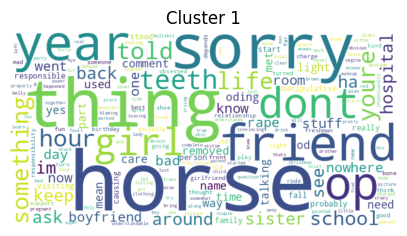

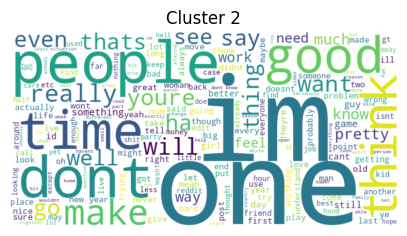

In [14]:
texts = []
# Generate and display word clouds for each cluster
for i in range(0, number_of_clusters):
    texts.append(" ".join(data[data['cluster'] == i]['body'].values))
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(texts[i])

    plt.figure(figsize=(5, 3))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')  
    plt.title(f"Cluster {i}")
    plt.show()

In the word clouds above we just put the most frequent words. Meaning there are word present in every cloud e.g. "one"

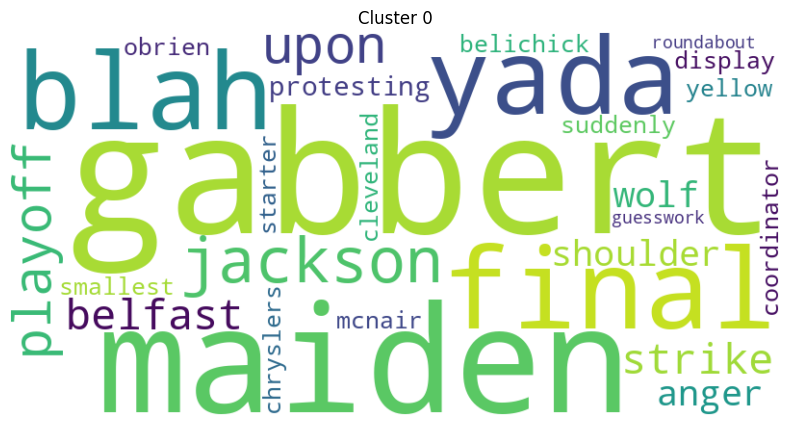

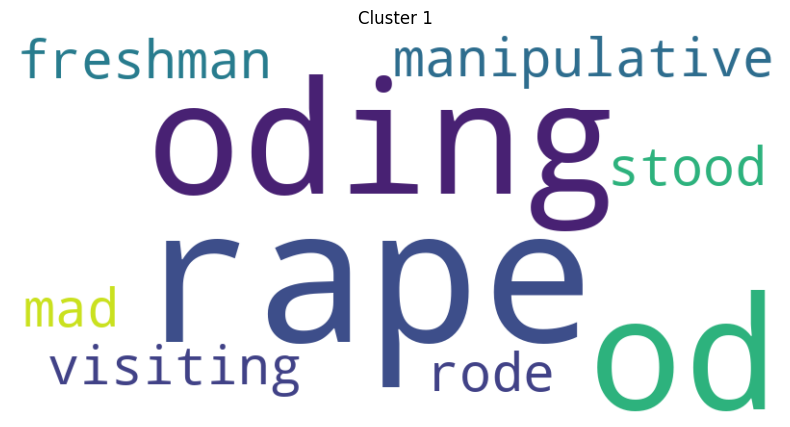

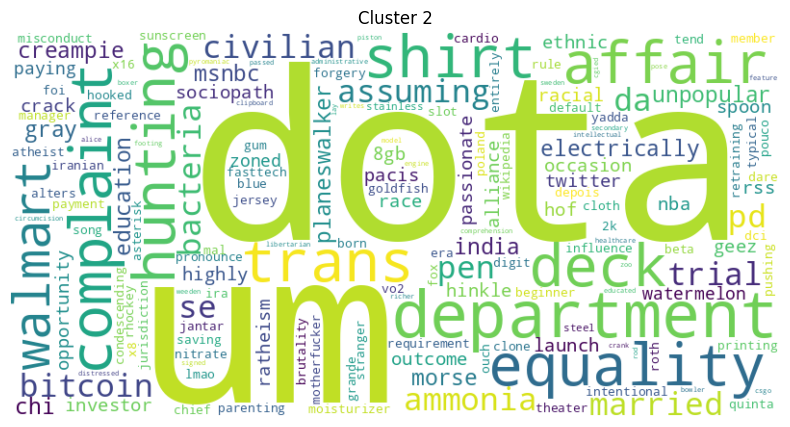

In [16]:
centroids = pd.DataFrame(
    best_birch.subcluster_centers_,
    columns= sorted(vectorizer.vocabulary_, key=vectorizer.vocabulary_.get)
)
# we want to only keep the features (columns) that have only one value different from 0
#meaning that we are only keeping the words that are present in one single cluster
listOfRelevantWords= centroids.loc[:, (centroids != 0).sum() == 1].dropna(axis=1).columns.tolist()
# Remove all words not in listOfRelevantWords from each string in texts
filtered_texts = []
relevant_set = set(listOfRelevantWords)
for t in texts:
    filtered = " ".join([w for w in t.split() if w in relevant_set])
    filtered_texts.append(filtered)

for i in range(0, number_of_clusters):
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(filtered_texts[i])

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.title(f"Cluster {i}")
    plt.axis('off')  
    plt.show()

<h2>Subreddit distribution</h2>

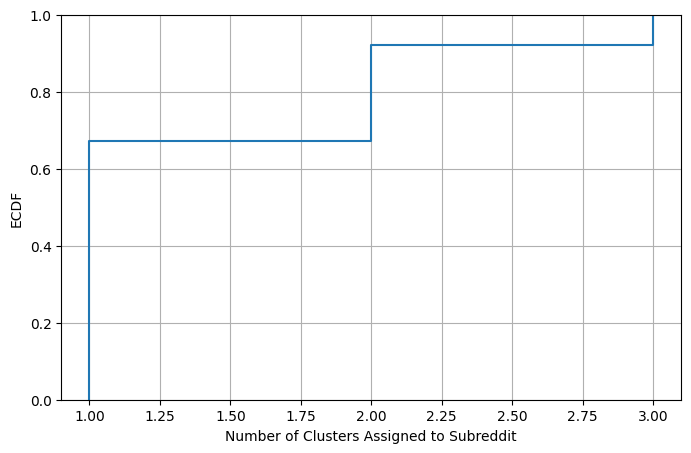

In [17]:
subreddit_cluster = data.groupby('subreddit')['cluster'].nunique().reset_index()#grouping by subreddit
#subreddit clusters is now a series with subreddit and number of clusters
subreddit_cluster.columns = ['subreddit', 'num_clusters']#turn it into a DF

# Filter subreddit_cluster to only those subreddits that have multiple comments
subreddits_with_multiple_comments = data.groupby('subreddit')['body'].nunique()
subreddits_with_multiple_comments = subreddits_with_multiple_comments[subreddits_with_multiple_comments > 1].index
subreddit_cluster = subreddit_cluster[subreddit_cluster['subreddit'].isin(subreddits_with_multiple_comments)]

plt.figure(figsize=(8, 5))
sns.ecdfplot(data=subreddit_cluster, x='num_clusters')
plt.xlabel('Number of Clusters Assigned to Subreddit')
plt.ylabel('ECDF')
plt.grid(True)
plt.show()

Cluster 0:


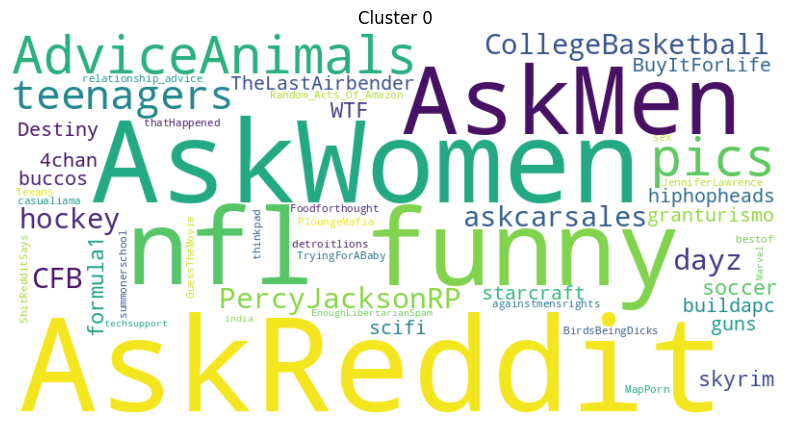

Cluster 1:


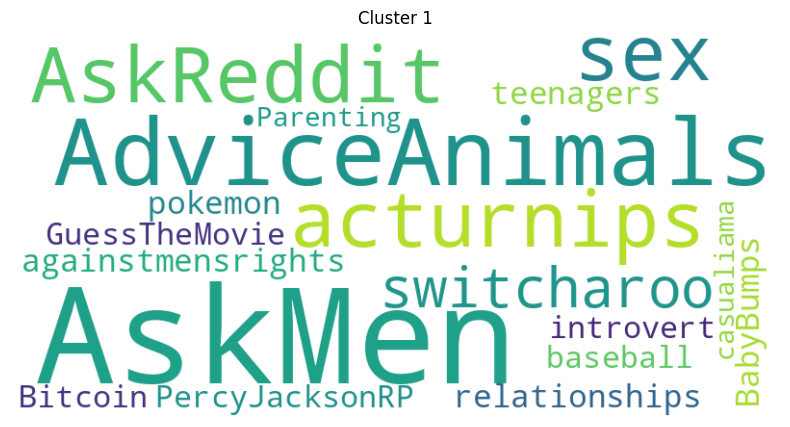

Cluster 2:


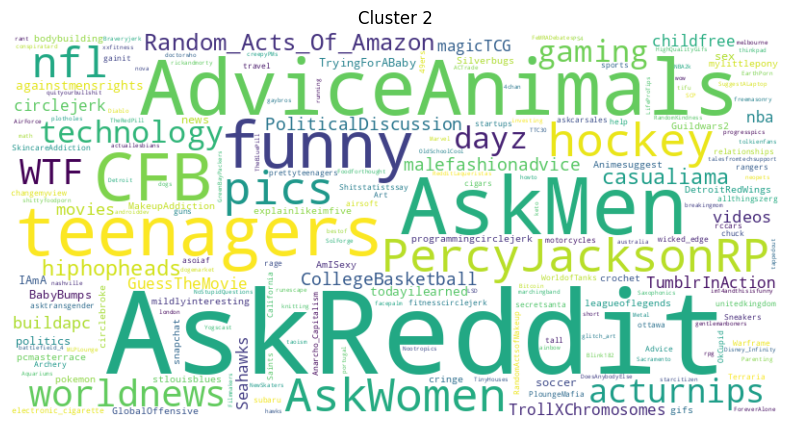

In [19]:
subredditsNames = []
for i in range(0, number_of_clusters):
    print(f"Cluster {i}:")
    subredditsNames.append(" ".join(data[data['cluster'] == i]['subreddit'].values))
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(subredditsNames[i])

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')  
    plt.title(f"Cluster {i}")
    plt.show()